In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("crop_yield.csv")


/tmp/ipykernel_2583/2623459518.py:1: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("crop_yield.csv")


In [3]:
print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (89810, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122.0,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140.0,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106.0,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146.0,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110.0,7.248251


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89810 entries, 0 to 89809
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  89810 non-null  object 
 1   Soil_Type               89810 non-null  object 
 2   Crop                    89810 non-null  object 
 3   Rainfall_mm             89810 non-null  float64
 4   Temperature_Celsius     89810 non-null  float64
 5   Fertilizer_Used         89809 non-null  object 
 6   Irrigation_Used         89809 non-null  object 
 7   Weather_Condition       89809 non-null  object 
 8   Days_to_Harvest         89809 non-null  float64
 9   Yield_tons_per_hectare  89809 non-null  float64
dtypes: float64(4), object(6)
memory usage: 6.9+ MB


In [4]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']


In [5]:
print(df.isnull().sum())

Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           1
Irrigation_Used           1
Weather_Condition         1
Days_to_Harvest           1
Yield_tons_per_hectare    1
dtype: int64


In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Crop"].value_counts()

,count
Crop,
Cotton,15035
Soybean,15007
Wheat,14984
Maize,14980
Rice,14966
Barley,14838


In [10]:
df["Region"].value_counts()

,count
Region,
West,22518
East,22466
North,22465
South,22361


In [12]:
df["Soil_Type"].value_counts()

,count
Soil_Type,
Silt,15069
Chalky,15001
Clay,14997
Sandy,14992
Peaty,14944
Loam,14807


In [13]:
df["Yield_tons_per_hectare"].describe()

,Yield_tons_per_hectare
count,89809.000000
mean,4.645970
std,1.693842
min,-0.841617
25%,3.418878
50%,4.650999
75%,5.867176
max,9.727004


In [14]:
# Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Rows with missing values:", len(missing_rows))

display(missing_rows)

Rows with missing values: 1


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
89809,South,Chalky,Cotton,967.214698,18.66481,NaN,NaN,NaN,NaN,NaN


In [15]:
# Distribution of crops
print("CROP DISTRIBUTION")
display(df["Crop"].value_counts())

# Distribution of regions
print("REGION DISTRIBUTION")
display(df["Region"].value_counts())

# Distribution of soil types
print("SOIL TYPE DISTRIBUTION")
display(df["Soil_Type"].value_counts())

# Distribution of weather conditions
print("WEATHER DISTRIBUTION")
display(df["Weather_Condition"].value_counts())

# Fertilizer and irrigation values
print("FERTILIZER VALUES")
display(df["Fertilizer_Used"].value_counts(dropna=False))

print("IRRIGATION VALUES")
display(df["Irrigation_Used"].value_counts(dropna=False))

CROP DISTRIBUTION


,count
Crop,
Cotton,15035
Soybean,15007
Wheat,14984
Maize,14980
Rice,14966
Barley,14838


REGION DISTRIBUTION


,count
Region,
West,22518
East,22466
North,22465
South,22361


SOIL TYPE DISTRIBUTION


,count
Soil_Type,
Silt,15069
Chalky,15001
Clay,14997
Sandy,14992
Peaty,14944
Loam,14807


... (2 outputs left out)

FERTILIZER VALUES


,count
Fertilizer_Used,
True,44910
False,44899
NaN,1


IRRIGATION VALUES


,count
Irrigation_Used,
True,44920
False,44889
NaN,1


In [16]:
# Statistical summary
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,89810.0,548.933677,259.680371,100.006823,323.923180,548.769276,773.318774,999.996116
Temperature_Celsius,89810.0,27.494617,7.211374,15.000202,21.249634,27.534268,33.723133,39.998947
Days_to_Harvest,89809.0,104.424022,25.959519,60.000000,82.000000,104.000000,127.000000,149.000000
Yield_tons_per_hectare,89809.0,4.645970,1.693842,-0.841617,3.418878,4.650999,5.867176,9.727004


In [21]:
# Check unique values
display(df.nunique())

,0
Region,4
Soil_Type,6
Crop,6
Rainfall_mm,89810
Temperature_Celsius,89810
Fertilizer_Used,2
Irrigation_Used,2
Weather_Condition,3
Days_to_Harvest,90
Yield_tons_per_hectare,89809


In [19]:
df.describe()

,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare
count,89810.000000,89810.000000,89809.000000,89809.000000
mean,548.933677,27.494617,104.424022,4.645970
std,259.680371,7.211374,25.959519,1.693842
min,100.006823,15.000202,60.000000,-0.841617
25%,323.923180,21.249634,82.000000,3.418878
50%,548.769276,27.534268,104.000000,4.650999
75%,773.318774,33.723133,127.000000,5.867176
max,999.996116,39.998947,149.000000,9.727004


In [22]:
# Find records with negative yield
negative_yield = df[df["Yield_tons_per_hectare"] < 0]

print("Number of negative yield records:", len(negative_yield))
display(negative_yield)

Number of negative yield records: 25


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
756,East,Peaty,Cotton,101.019421,33.804131,False,False,Rainy,117.0,-0.007103
7799,South,Chalky,Rice,108.804894,18.004082,False,False,Sunny,86.0,-0.061283
8421,East,Chalky,Soybean,168.120735,38.473430,False,False,Cloudy,111.0,-0.119911
9553,North,Silt,Wheat,156.607973,16.610257,False,False,Sunny,129.0,-0.193093
15435,South,Chalky,Maize,177.481344,27.719742,False,False,Sunny,94.0,-0.009811
19517,North,Clay,Maize,107.845638,21.855075,False,False,Rainy,118.0,-0.265207
22552,East,Sandy,Barley,136.608277,16.723985,False,False,Sunny,101.0,-0.235296
25967,West,Sandy,Wheat,143.407729,16.252040,False,False,Rainy,77.0,-0.023612
33285,West,Sandy,Rice,103.921766,16.314536,False,False,Cloudy,80.0,-0.060267
34902,East,Chalky,Soybean,144.431171,37.817570,False,False,Sunny,112.0,-0.028898


In [23]:
# Remove rows where the target variable is missing
df = df.dropna(subset=["Yield_tons_per_hectare"]).copy()

In [25]:
df.shape

(89809, 10)

In [26]:
print(df.isnull().sum())

Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64


In [27]:
# Create a copy of the original dataset
df_clean = df.copy()

# Record original number of observations
original_rows = len(df_clean)

# Remove records with missing target values
df_clean = df_clean.dropna(
    subset=["Yield_tons_per_hectare"]
)

# Remove records with physically impossible negative yields
df_clean = df_clean[
    df_clean["Yield_tons_per_hectare"] >= 0
].copy()

# Display cleaning summary
print("Original observations:", original_rows)
print("Cleaned observations:", len(df_clean))
print("Total records removed:", original_rows - len(df_clean))
print("Remaining missing values:")
display(df_clean.isnull().sum())

print("Remaining negative yields:",
      (df_clean["Yield_tons_per_hectare"] < 0).sum())

Original observations: 89809
Cleaned observations: 89784
Total records removed: 25
Remaining missing values:


,0
Region,0
Soil_Type,0
Crop,0
Rainfall_mm,0
Temperature_Celsius,0
Fertilizer_Used,0
Irrigation_Used,0
Weather_Condition,0
Days_to_Harvest,0
Yield_tons_per_hectare,0


Remaining negative yields: 0


In [34]:
# Average yield by crop
crop_yield = (
    df_clean.groupby("Crop")["Yield_tons_per_hectare"]
    .agg(["mean", "median", "min", "max", "count"])
    .sort_values("mean", ascending=False)
)

display(crop_yield)

# Average yield by soil type
soil_yield = (
    df_clean.groupby("Soil_Type")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

display(soil_yield)

# Average yield by fertilizer usage
fertilizer_usage =(
    df_clean.groupby("Fertilizer_Used")[
        "Yield_tons_per_hectare"
    ].mean()
)
display(fertilizer_usage)

# Average yield by irrigation usage
irrigation_usage = (
    df_clean.groupby("Irrigation_Used")[
        "Yield_tons_per_hectare"
    ].mean()
)
display(irrigation_usage)

,mean,median,min,max,count
Crop,,,,,
Barley,4.670253,4.686959,0.005463,9.387372,14832
Wheat,4.647337,4.650779,0.021940,9.727004,14980
Maize,4.643339,4.638207,0.013090,9.559016,14976
Cotton,4.642931,4.638461,0.085745,9.253249,15030
Rice,4.641781,4.651347,0.009086,9.320256,14964
Soybean,4.638436,4.651908,0.064146,9.432116,15002


,Yield_tons_per_hectare
Soil_Type,
Chalky,4.657797
Peaty,4.656999
Clay,4.651093
Sandy,4.646352
Silt,4.644739
Loam,4.626634


,Yield_tons_per_hectare
Fertilizer_Used,
False,3.892141
True,5.401864


,Yield_tons_per_hectare
Irrigation_Used,
False,4.049517
True,5.244347


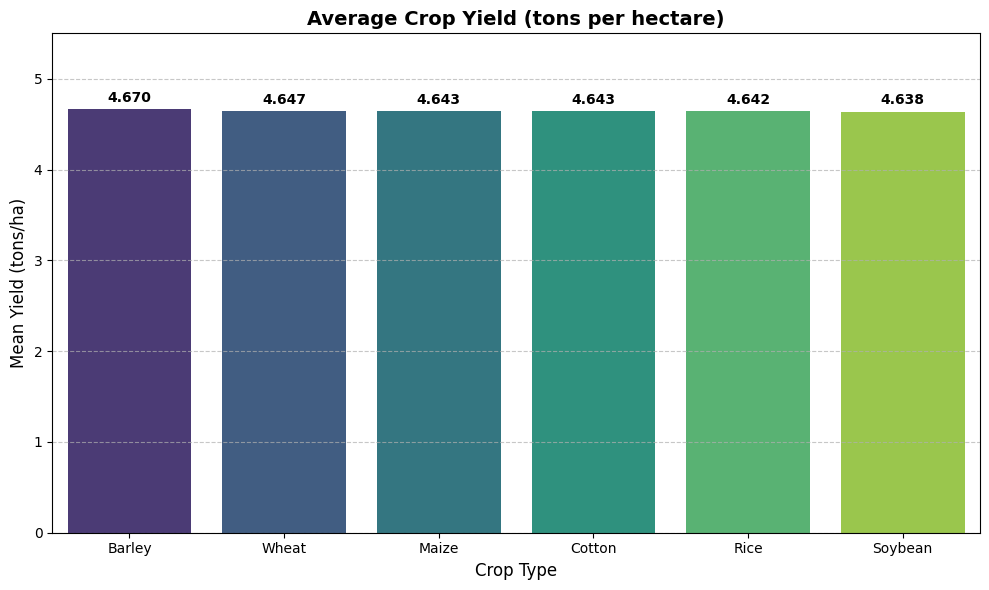

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# Reset index of crop_yield to make 'Crop' a column
crop_yield_df = crop_yield.reset_index()

# Create the bar chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='Crop',
    y='mean',
    data=crop_yield_df,
    palette='viridis',
    hue='Crop',
    legend=False
)

# Add data labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10, fontweight='bold')

# Customize the chart labels and title
plt.title('Average Crop Yield (tons per hectare)', fontsize=14, fontweight='bold')
plt.xlabel('Crop Type', fontsize=12)
plt.ylabel('Mean Yield (tons/ha)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 5.5)  # Set a limit to leave room for the labels

# Show the plot
plt.tight_layout()
plt.show()

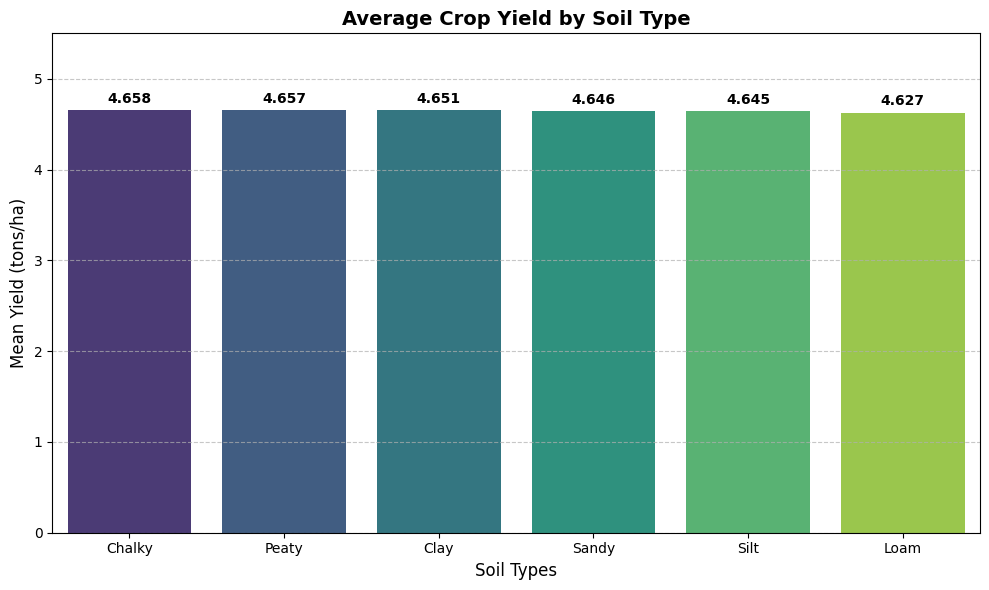

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# Reset index of soil_yield to make 'Soil_Type' a column
soil_yield_df = soil_yield.reset_index()
# Rename the value column to 'mean' to match the plotting code
soil_yield_df.columns = ['Soil_Type', 'mean']

# Create the bar chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='Soil_Type',
    y='mean',
    data=soil_yield_df,
    palette='viridis',
    hue='Soil_Type',
    legend=False
)

# Add data labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10, fontweight='bold')

# Customize the chart labels and title
plt.title('Average Crop Yield by Soil Type', fontsize=14, fontweight='bold')
plt.xlabel('Soil Types', fontsize=12)
plt.ylabel('Mean Yield (tons/ha)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 5.5)  # Set a limit to leave room for the labels

# Show the plot
plt.tight_layout()
plt.show()

In [36]:
# Select numerical columns
numerical_df = df_clean.select_dtypes(include=["number"])

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display correlation with crop yield
display(
    correlation_matrix["Yield_tons_per_hectare"]
    .sort_values(ascending=False)
)

,Yield_tons_per_hectare
Yield_tons_per_hectare,1.000000
Rainfall_mm,0.762497
Temperature_Celsius,0.083528
Days_to_Harvest,0.000806


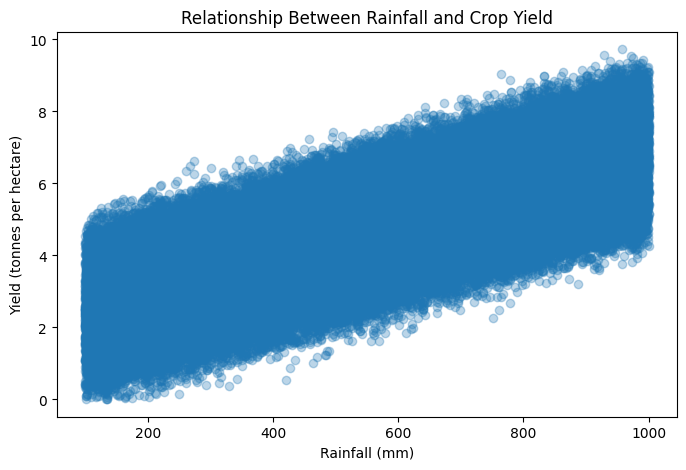

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Rainfall_mm"],
    df_clean["Yield_tons_per_hectare"],
    alpha=0.3
)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (tonnes per hectare)")
plt.title("Relationship Between Rainfall and Crop Yield")

plt.show()

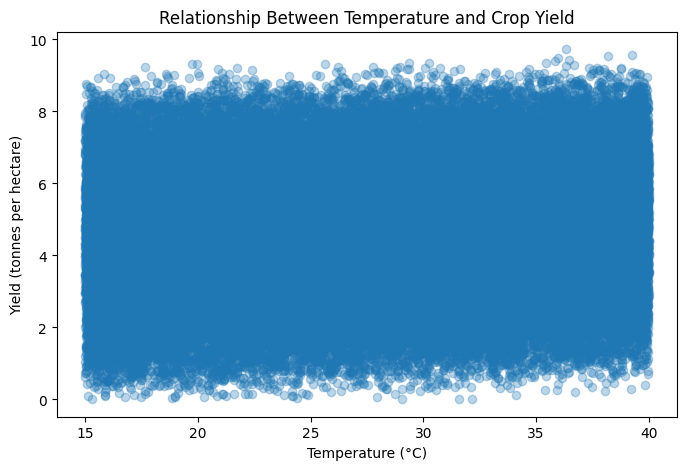

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Temperature_Celsius"],
    df_clean["Yield_tons_per_hectare"],
    alpha=0.3
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Yield (tonnes per hectare)")
plt.title("Relationship Between Temperature and Crop Yield")

plt.show()

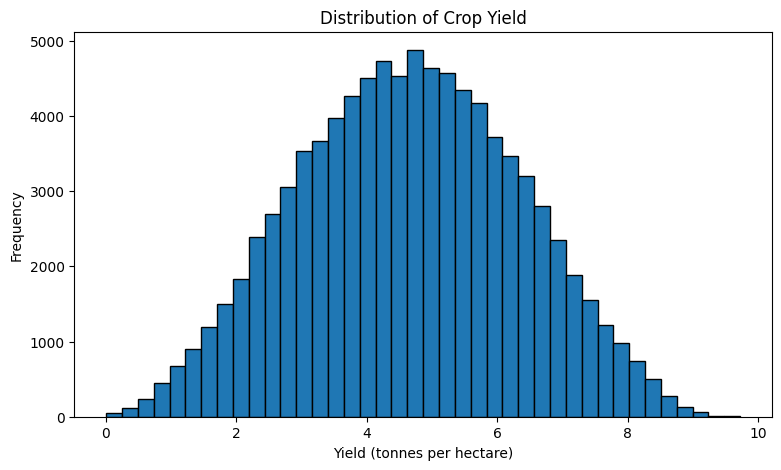

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["Yield_tons_per_hectare"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("Yield (tonnes per hectare)")
plt.ylabel("Frequency")
plt.title("Distribution of Crop Yield")

plt.show()

In [40]:
print("Skewness:", df_clean["Yield_tons_per_hectare"].skew())

print("Kurtosis:", df_clean["Yield_tons_per_hectare"].kurt())

Skewness: 0.003454872876340501
Kurtosis: -0.5283691474487173


In [42]:
df_clean.columns

Index(['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius',
       'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition',
       'Days_to_Harvest', 'Yield_tons_per_hectare'],
      dtype='object')

In [44]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89784 entries, 0 to 89808
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  89784 non-null  object 
 1   Soil_Type               89784 non-null  object 
 2   Crop                    89784 non-null  object 
 3   Rainfall_mm             89784 non-null  float64
 4   Temperature_Celsius     89784 non-null  float64
 5   Fertilizer_Used         89784 non-null  object 
 6   Irrigation_Used         89784 non-null  object 
 7   Weather_Condition       89784 non-null  object 
 8   Days_to_Harvest         89784 non-null  float64
 9   Yield_tons_per_hectare  89784 non-null  float64
dtypes: float64(4), object(6)
memory usage: 7.5+ MB


In [50]:
target = "Yield_tons_per_hectare"

X = df_clean.drop(columns=[target])
y = df[target]

In [46]:
y

,Yield_tons_per_hectare
0,6.555816
1,8.527341
2,1.127443
3,6.517573
4,7.248251
...,...
89804,2.710626
89805,2.248437
89806,2.890704
89807,6.389306


In [47]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [51]:
# Align y with the cleaned X dataframe
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [52]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

predictions = linear_model.predict(X_test)

In [53]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.3979268298277636
RMSE: 0.4974706516726836
R²: 0.91421684856136


In [54]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(
    "Random Forest MAE:",
    mean_absolute_error(y_test, rf_predictions)
)

print(
    "Random Forest RMSE:",
    np.sqrt(mean_squared_error(y_test, rf_predictions))
)

print(
    "Random Forest R²:",
    r2_score(y_test, rf_predictions)
)

Random Forest MAE: 0.41338006905282426
Random Forest RMSE: 0.5168214901516313
Random Forest R²: 0.9074133872960418


In [55]:
def predict_yield(custom_data):
    # Convert custom data dictionary to a DataFrame
    input_df = pd.DataFrame([custom_data])

    # Ensure all required features are present in the correct order
    input_df = input_df[X.columns]

    # Make predictions using both pipelines
    linear_pred = linear_model.predict(input_df)[0]
    rf_pred = rf_model.predict(input_df)[0]

    print("--- Yield Prediction Report ---")
    print(f"Linear Regression Model Prediction: {linear_pred:.3f} tons per hectare")
    print(f"Random Forest Model Prediction:     {rf_pred:.3f} tons per hectare")

# Define custom testing features. Feel free to modify these values to test different scenarios!
sample_input = {
    'Region': 'West',
    'Soil_Type': 'Sandy',
    'Crop': 'Cotton',
    'Rainfall_mm': 850.0,
    'Temperature_Celsius': 28.0,
    'Fertilizer_Used': 'True',
    'Irrigation_Used': 'True',
    'Weather_Condition': 'Sunny',
    'Days_to_Harvest': 120.0
}

predict_yield(sample_input)

--- Yield Prediction Report ---
Linear Regression Model Prediction: 6.159 tons per hectare
Random Forest Model Prediction:     6.016 tons per hectare


In [56]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create interactive input widgets for each feature
region_widget = widgets.Dropdown(options=sorted(df_clean['Region'].unique()), description='Region:')
soil_widget = widgets.Dropdown(options=sorted(df_clean['Soil_Type'].unique()), description='Soil Type:')
crop_widget = widgets.Dropdown(options=sorted(df_clean['Crop'].unique()), description='Crop:')
weather_widget = widgets.Dropdown(options=sorted(df_clean['Weather_Condition'].unique()), description='Weather:')

fertilizer_widget = widgets.Dropdown(options=['True', 'False'], description='Fertilizer:')
irrigation_widget = widgets.Dropdown(options=['True', 'False'], description='Irrigation:')

rainfall_widget = widgets.FloatText(value=500.0, description='Rainfall (mm):')
temp_widget = widgets.FloatText(value=25.0, description='Temp (°C):')
harvest_widget = widgets.FloatText(value=100.0, description='Days to Harvest:')

predict_button = widgets.Button(description='Predict Yield', button_style='success', icon='calculator')
output_area = widgets.Output()

def on_predict_clicked(b):
    with output_area:
        clear_output()
        # Collect current widget values into a dictionary
        user_inputs = {
            'Region': region_widget.value,
            'Soil_Type': soil_widget.value,
            'Crop': crop_widget.value,
            'Rainfall_mm': rainfall_widget.value,
            'Temperature_Celsius': temp_widget.value,
            'Fertilizer_Used': fertilizer_widget.value,
            'Irrigation_Used': irrigation_widget.value,
            'Weather_Condition': weather_widget.value,
            'Days_to_Harvest': harvest_widget.value
        }

        # Convert inputs to a DataFrame with aligned columns
        input_df = pd.DataFrame([user_inputs])
        input_df = input_df[X.columns]

        # Run prediction through pipelines
        lr_pred = linear_model.predict(input_df)[0]
        rf_pred = rf_model.predict(input_df)[0]

        # Display results neatly
        print("=========================================")
        print("         YIELD PREDICTION RESULTS        ")
        print("=========================================")
        print(f"Linear Regression Prediction : {lr_pred:.3f} tons/hectare")
        print(f"Random Forest Prediction    : {rf_pred:.3f} tons/hectare")
        print("=========================================")

predict_button.on_click(on_predict_clicked)

# Group and display the widgets in a clean layout
inputs_box = widgets.VBox([
    widgets.HTML("<h3>Enter Crop Parameters</h3>"),
    widgets.HBox([region_widget, soil_widget]),
    widgets.HBox([crop_widget, weather_widget]),
    widgets.HBox([fertilizer_widget, irrigation_widget]),
    widgets.HBox([rainfall_widget, temp_widget, harvest_widget]),
    widgets.HTML("<br>"),
    predict_button,
    output_area
])

display(inputs_box)

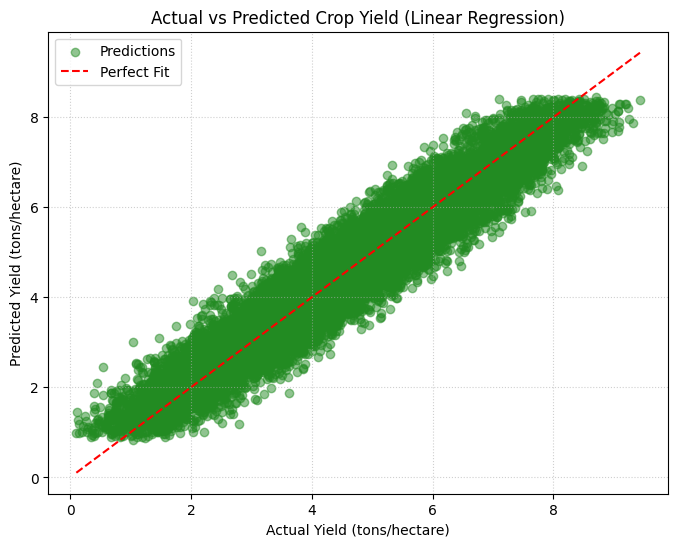

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Using the correct variable name 'predictions'
plt.scatter(y_test, predictions, alpha=0.5, color='forestgreen', label='Predictions')

# Reference line representing perfect prediction
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    label='Perfect Fit'
)

plt.xlabel("Actual Yield (tons/hectare)")
plt.ylabel("Predicted Yield (tons/hectare)")
plt.title("Actual vs Predicted Crop Yield (Linear Regression)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

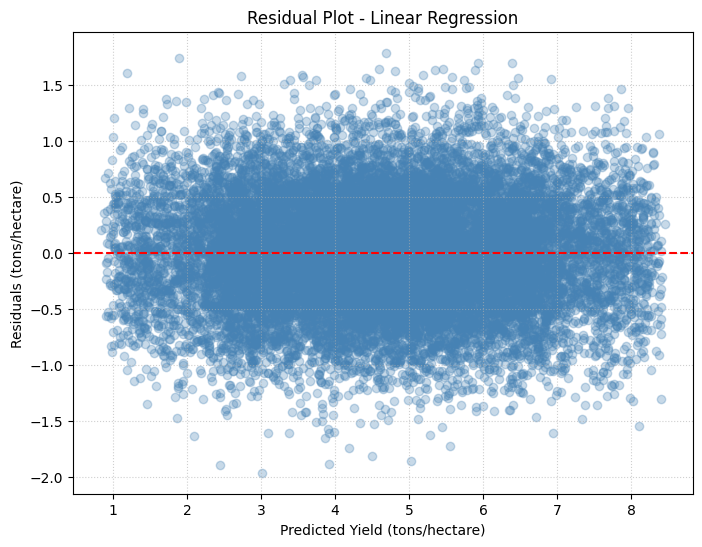

In [60]:
# Calculate residuals using the correct variable name 'predictions'
residuals = y_test - predictions

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Scatter plot of predictions vs residuals
plt.scatter(predictions, residuals, alpha=0.3, color='steelblue')

# Reference line at residual = 0
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Yield (tons/hectare)")
plt.ylabel("Residuals (tons/hectare)")
plt.title("Residual Plot - Linear Regression")
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()